# Team12 · Обнаружение токсичного контента
## Эксперименты и данные 

**Задача:** классификация русскоязычных комментариев на `neutral`, `offensive`, `toxic`. Ноутбук содержит EDA, воспроизводимое сравнение трёх моделей, оценку ошибок и **пайплайн обновления модели на одобренной разметке из БД**.

Архив `dataset.txt.zip` положите рядом с ноутбуком или укажите путь в `DATA_PATH`. 

**Особенность данных:** в исходном наборе четыре взаимоисключающие метки. Для трёх классов применяется рабочее правило `NORMAL → neutral`, `INSULT/OBSCENITY → offensive`, `THREAT → toxic`. Это операционное определение для эксперимента: другие формы агрессии без угроз могут отсутствовать в классе `toxic`. Его стоит уточнить командой перед продакшеном.

In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib sqlalchemy
import os, re, json, zipfile, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
import joblib
SEED = 42
DATA_PATH = Path(os.environ.get('DATA_PATH', 'dataset.txt'))
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
CLASSES = ['neutral', 'offensive', 'toxic']
LABEL_MAP = {'NORMAL':'neutral','INSULT':'offensive','OBSCENITY':'offensive','THREAT':'toxic'}
print('Файл:', DATA_PATH, '| существует:', DATA_PATH.exists())


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Файл: dataset.txt | существует: True


## 1. Загрузка и валидация данных
Формат строки: `__label__INSULT текст комментария`. Если путь указывает на ZIP, читаем `dataset.txt` **напрямую из архива**. Некорректные строки учитываем и исключаем.

In [4]:
def load_dataset(path):
    if not path.exists():
        raise FileNotFoundError(f'Не найден {path}. Укажите DATA_PATH или положите ZIP рядом с ноутбуком.')
    records = []; malformed = 0
    if path.suffix.lower() == '.zip':
        zf = zipfile.ZipFile(path)
        names = [n for n in zf.namelist() if n.endswith('.txt') and not n.startswith('__MACOSX')]
        if not names: raise ValueError('В архиве нет .txt')
        stream = zf.open(names[0])
    else:
        zf = None; stream = open(path,'rb')
    try:
        for line in stream:
            line = line.decode('utf-8',errors='replace').strip()
            match = re.match(r'^__label__(\w+)\s+(.+)$',line)
            if not match or match.group(1) not in LABEL_MAP:
                malformed += 1; continue
            records.append((match.group(2),match.group(1),LABEL_MAP[match.group(1)]))
    finally:
        stream.close()
        if zf is not None: zf.close()
    return pd.DataFrame(records, columns=['text','source_label','label']), malformed
raw, malformed = load_dataset(DATA_PATH)
print('Строк:',len(raw),'| неверный формат:',malformed)
print('Пропуски:',raw.isna().sum().to_dict())
print('Исходные метки:'); display(raw.source_label.value_counts().to_frame('count'))
assert set(raw.label.unique()) <= set(CLASSES)

Строк: 239957 | неверный формат: 8333
Пропуски: {'text': 0, 'source_label': 0, 'label': 0}
Исходные метки:


,count
source_label,
NORMAL,203685
INSULT,28567
THREAT,5460
OBSCENITY,2245


## 2. EDA: распределения, дубликаты, длина комментариев
Визуализации создаются из реальных данных. Тексты комментариев не публикуются в отчёте без дополнительной проверки, поскольку могут содержать грубую лексику и персональные данные.

Уникальных текстов: 239950 | полных дубликатов: 6
Текстов с конфликтующими метками: 1


,n,median_chars,p95_chars,median_words
label,,,,
neutral,203685,46.0,252.00,7.0
offensive,30812,54.0,265.00,9.0
toxic,5460,40.0,153.05,7.0


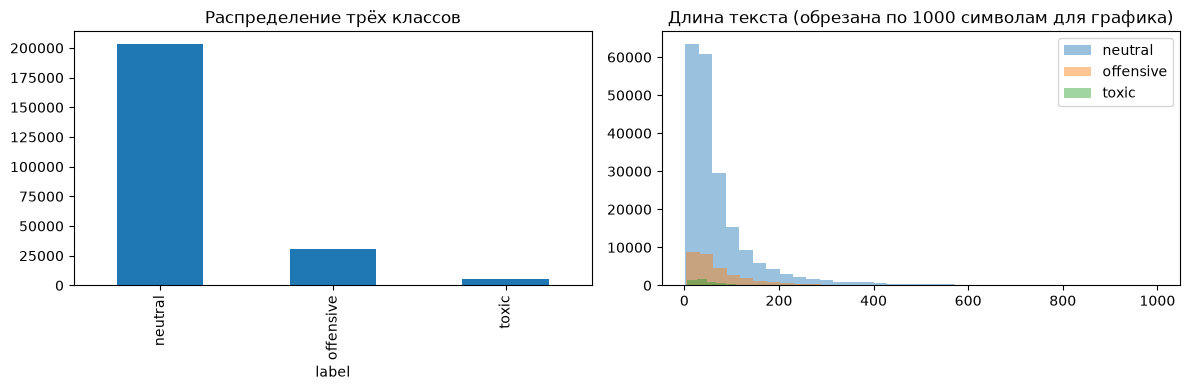

In [5]:
raw['length_chars'] = raw.text.str.len()
raw['length_words'] = raw.text.str.split().str.len()
print('Уникальных текстов:',raw.text.nunique(),'| полных дубликатов:',raw.duplicated().sum())
print('Текстов с конфликтующими метками:',(raw.groupby('text').label.nunique()>1).sum())
display(raw.groupby('label').agg(n=('text','size'),median_chars=('length_chars','median'),p95_chars=('length_chars',lambda s:s.quantile(.95)),median_words=('length_words','median')).reindex(CLASSES))
fig, axes = plt.subplots(1,2,figsize=(12,4))
raw.label.value_counts().reindex(CLASSES).plot.bar(ax=axes[0],title='Распределение трёх классов')
for k in CLASSES:
    axes[1].hist(raw.loc[raw.label==k,'length_chars'].clip(upper=1000),bins=35,alpha=.45,label=k)
axes[1].set_title('Длина текста (обрезана по 1000 символам для графика)');axes[1].legend()
plt.tight_layout();plt.show()

## 3. Подготовка данных без утечки
Сначала нормализуем пробелы и регистр, затем удаляем точные дубликаты нормализованного текста. Если у одинаковых текстов разные метки, исключаем конфликтующие тексты, а не выбираем метку произвольно. Разделяем на train/validation/test **до** построения TF-IDF. Для сравнения с обновлённой моделью test фиксируем и не добавляем в обучающие данные.

In [6]:
def normalize_text(text):
    text = str(text).lower().replace('ё','е')
    text = re.sub(r'\s+',' ',text).strip()
    return text
raw['text_clean'] = raw.text.map(normalize_text)
raw = raw[raw.text_clean.str.len()>0].copy()
conflicts = raw.groupby('text_clean').label.nunique()
conflict_texts = set(conflicts[conflicts>1].index)
clean = raw[~raw.text_clean.isin(conflict_texts)].drop_duplicates('text_clean').copy()
print('Исключено конфликтующих уникальных текстов:',len(conflict_texts))
print('После дедупликации:',len(clean))
train_val,test = train_test_split(clean[['text_clean','label']],test_size=.15,random_state=SEED,stratify=clean.label)
train,valid = train_test_split(train_val,test_size=.15/.85,random_state=SEED,stratify=train_val.label)
for name,frame in [('train',train),('valid',valid),('test',test)]:
    print(name,len(frame),frame.label.value_counts().reindex(CLASSES,fill_value=0).to_dict())
assert set(train.text_clean).isdisjoint(test.text_clean)
assert set(valid.text_clean).isdisjoint(test.text_clean)
# Контрольный тест хранится отдельно и не должен поступать в БД для дообучения.
TEST_HASHES = set(test.text_clean.map(lambda x:hashlib.sha256(x.encode('utf-8')).hexdigest()))

Исключено конфликтующих уникальных текстов: 1
После дедупликации: 239900
train 167930 {'neutral': 142553, 'offensive': 21558, 'toxic': 3819}
valid 35985 {'neutral': 30547, 'offensive': 4619, 'toxic': 819}
test 35985 {'neutral': 30547, 'offensive': 4619, 'toxic': 819}


## 4. Базовые модели и выбор по Macro-F1 на validation
TF-IDF обучается только на train внутри `Pipeline`. Модели: Multinomial Naive Bayes, Logistic Regression (с балансировкой классов) и линейный SGD SVM (hinge). Для ускорения используется ограничение `max_features=100000`. Полный набор train используется по умолчанию; для слабого компьютера можно задать `MAX_TRAIN_ROWS` через переменную окружения, и это будет явно отображено.

In [7]:
MAX_TRAIN_ROWS = int(os.environ.get('MAX_TRAIN_ROWS','0'))
train_fit = train
if MAX_TRAIN_ROWS and MAX_TRAIN_ROWS < len(train):
    train_fit,_ = train_test_split(train,train_size=MAX_TRAIN_ROWS,random_state=SEED,stratify=train.label)
print('Обучающих примеров:',len(train_fit),'из',len(train))
def make_pipeline(model):
    return Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_df=.98,max_features=100000,sublinear_tf=True)),('clf',model)])
model_factories = {
    'Naive Bayes':lambda:make_pipeline(MultinomialNB(alpha=1.0)),
    'Logistic Regression':lambda:make_pipeline(LogisticRegression(max_iter=1000,class_weight='balanced',random_state=SEED)),
    'Linear SVM (SGD)':lambda:make_pipeline(SGDClassifier(loss='hinge',class_weight='balanced',random_state=SEED,max_iter=1000,tol=1e-3)),
}
fitted={}; rows=[]
for name, factory in model_factories.items():
    model=factory().fit(train_fit.text_clean,train_fit.label)
    pred=model.predict(valid.text_clean)
    rows.append({'model':name,'accuracy_val':accuracy_score(valid.label,pred),'macro_f1_val':f1_score(valid.label,pred,labels=CLASSES,average='macro',zero_division=0),'weighted_f1_val':f1_score(valid.label,pred,labels=CLASSES,average='weighted',zero_division=0)})
    fitted[name]=model
comparison=pd.DataFrame(rows).sort_values('macro_f1_val',ascending=False).reset_index(drop=True)
display(comparison.round(4))
comparison.to_csv(ARTIFACTS/'validation_comparison.csv',index=False)

Обучающих примеров: 167930 из 167930


,model,accuracy_val,macro_f1_val,weighted_f1_val
0,Logistic Regression,0.9416,0.8513,0.9430
1,Linear SVM (SGD),0.9284,0.8173,0.9216
2,Naive Bayes,0.9149,0.6322,0.8993


## 5. Честная оценка на фиксированном тесте
Выбираем победителя **только по validation**, после этого **однократно** вычисляем тестовые метрики. Особое внимание — полноте класса `toxic`, Macro-F1 и ошибкам между `toxic`/`offensive`.

Лучшая модель: Logistic Regression
Test Accuracy: 0.9433
Test Macro-F1: 0.8572


,precision,recall,f1-score,support
neutral,0.9766,0.9603,0.9684,30547.0000
offensive,0.7868,0.8420,0.8134,4619.0000
toxic,0.7160,0.8803,0.7897,819.0000
accuracy,0.9433,0.9433,0.9433,0.9433
macro avg,0.8265,0.8942,0.8572,35985.0000
weighted avg,0.9463,0.9433,0.9444,35985.0000


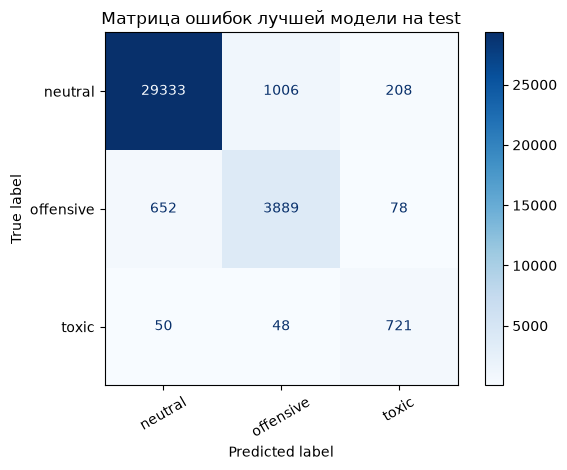

Модель и метрики сохранены в artifacts


In [8]:
best_name=comparison.loc[0,'model']; champion=fitted[best_name]
y_pred=champion.predict(test.text_clean)
print('Лучшая модель:',best_name)
print('Test Accuracy:',round(accuracy_score(test.label,y_pred),4))
print('Test Macro-F1:',round(f1_score(test.label,y_pred,labels=CLASSES,average='macro',zero_division=0),4))
report=classification_report(test.label,y_pred,labels=CLASSES,output_dict=True,zero_division=0)
display(pd.DataFrame(report).T.round(4))
ConfusionMatrixDisplay.from_predictions(test.label,y_pred,labels=CLASSES,xticks_rotation=30,cmap='Blues',values_format='d')
plt.title('Матрица ошибок лучшей модели на test');plt.tight_layout();plt.show()
pd.DataFrame(report).T.to_csv(ARTIFACTS/'test_report.csv')
joblib.dump(champion,ARTIFACTS/'baseline_model.joblib')
metadata={'model':best_name,'classes':CLASSES,'seed':SEED,'train_rows':len(train_fit),'val_rows':len(valid),'test_rows':len(test),'test_macro_f1':report['macro avg']['f1-score'],'test_toxic_recall':report['toxic']['recall'],'dataset_sha256':hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()}
(ARTIFACTS/'baseline_metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
print('Модель и метрики сохранены в',ARTIFACTS)

## 6. Пайплайн обновления на размеченных комментариях из БД

**Контракт с разделом «Архитектура и сервис» (Егор):** SQL-запрос должен вернуть колонки `comment_id`, `text`, `label`, `reviewed_at` с комментариями, подтверждёнными человеком (например, `status='approved'`). Требуются одни из меток `neutral/offensive/toxic` (допускаются исходные `NORMAL/INSULT/OBSCENITY/THREAT`). **Никаких предсказаний модели как истинных меток.**

Подключение: `DB_URL` через переменную окружения (например, `sqlite:///moderation.db` или SQLAlchemy URL вашей СУБД). Запрос задаётся `DB_APPROVED_QUERY` и должен быть составлен командой под реальную схему. Значения доступов **не** сохраняются в ноутбуке. Если соединение не настроено, учебный раздел пропускается.

**Важно:** классический TF-IDF + LR/SVM не поддерживает безопасное обычное `partial_fit` внутри указанного пайплайна. Здесь **дообучение реализовано как переобучение с нуля на исходном train + новых проверенных данных**, с сохранением фиксированных validation/test. Это реальный воспроизводимый retraining-пайплайн, а не имитация инкрементального обучения. Избегаем утечки: исключаем тексты, совпадающие с test/validation; проверяем дубликаты и конфликты. Для продакшена необходимы управление версиями данных, права на выгрузку и аудит разметки.

In [11]:
DB_URL = os.environ.get('DB_URL','')
DB_APPROVED_QUERY = os.environ.get('DB_APPROVED_QUERY','')
# Пример только для согласованной схемы таблицы:
# SELECT id AS comment_id, body AS text, human_label AS label, reviewed_at
# FROM moderation_comments WHERE status = 'approved' AND human_label IS NOT NULL

def fetch_approved_from_db(url,query):
    if not url or not query:
        print('Подключение к БД не настроено. Задайте DB_URL и DB_APPROVED_QUERY.')
        return pd.DataFrame(columns=['comment_id','text','label','reviewed_at'])
    try:
        from sqlalchemy import create_engine, text as sql_text
    except ImportError as e:
        raise ImportError('Установите sqlalchemy и драйвер вашей БД') from e
    engine=create_engine(url)
    try:
        with engine.connect() as conn:
            data=pd.read_sql_query(sql_text(query),conn)
    finally:
        engine.dispose()
    required={'comment_id','text','label','reviewed_at'}
    if not required.issubset(data.columns):
        raise ValueError(f'В запросе отсутствуют колонки: {required-set(data.columns)}')
    return data

def prepare_db_data(db_df, train_df, valid_df, test_df):
    if db_df.empty: return pd.DataFrame(columns=['text_clean','label'])
    x=db_df.copy()
    x=x.dropna(subset=['comment_id','text','label','reviewed_at'])
    mapper={**LABEL_MAP,**{s:s for s in CLASSES}}
    x['label']=x['label'].astype(str).str.strip().map(mapper)
    x=x.dropna(subset=['label'])
    x['text_clean']=x.text.map(normalize_text)
    x=x[x.text_clean.str.len()>0]
    # exclude anything in held-out sets, regardless of label
    heldout=set(valid_df.text_clean)|set(test_df.text_clean)
    x=x[~x.text_clean.isin(heldout)]
    # source training labels take priority; conflicts with existing train excluded
    train_labels=train_df.set_index('text_clean').label.to_dict()
    x=x[~x.text_clean.isin(set(train_labels))]
    ambiguous=x.groupby('text_clean').label.nunique()
    x=x[~x.text_clean.isin(set(ambiguous[ambiguous>1].index))]
    x=x.drop_duplicates('text_clean')
    return x[['text_clean','label']].reset_index(drop=True)

db_rows=fetch_approved_from_db(DB_URL,DB_APPROVED_QUERY)
new_data=prepare_db_data(db_rows,train,valid,test)
print('Одобренных строк из БД:',len(db_rows),'| новых пригодных примеров:',len(new_data))
if len(new_data):display(new_data.label.value_counts().reindex(CLASSES,fill_value=0).to_frame('new_count'))

Подключение к БД не настроено. Задайте DB_URL и DB_APPROVED_QUERY.
Одобренных строк из БД: 0 | новых пригодных примеров: 0


## 7. Retraining и контроль качества перед публикацией
Кандидат обучается на `train + DB`, а оценка выполняется на старой фиксированной validation. Сравниваются **Macro-F1**, recall класса `toxic` и минимум примеров по классам. Кандидат сохраняется отдельно, без автоматической замены основной модели. Если накопленные метки изменили распределение, рекомендуется новая независимая ручная тестовая выборка для проверки сдвига домена.

**Правило допуска (демонстрационное):** Macro-F1 не ниже базового более чем на 0.01, recall `toxic` не ниже базового более чем на 0.02. Дополнительная проверка и выпуск в сервис — зона ответственности Егора и Александра.

In [12]:
MIN_NEW_ROWS=int(os.environ.get('MIN_NEW_ROWS','30'))
if len(new_data)<MIN_NEW_ROWS:
    print(f'Переобучение пропущено: {len(new_data)} новых размеченных строк, минимум {MIN_NEW_ROWS}.')
else:
    # Начинаем с победившей конфигурации и обучаем на полном исходном train + новой разметке
    augmented=pd.concat([train,new_data],ignore_index=True)
    candidate=model_factories[best_name]().fit(augmented.text_clean,augmented.label)
    base_pred=champion.predict(valid.text_clean)
    cand_pred=candidate.predict(valid.text_clean)
    base_f1=f1_score(valid.label,base_pred,labels=CLASSES,average='macro',zero_division=0)
    cand_f1=f1_score(valid.label,cand_pred,labels=CLASSES,average='macro',zero_division=0)
    base_recall=classification_report(valid.label,base_pred,labels=CLASSES,output_dict=True,zero_division=0)['toxic']['recall']
    cand_recall=classification_report(valid.label,cand_pred,labels=CLASSES,output_dict=True,zero_division=0)['toxic']['recall']
    approved=(cand_f1>=base_f1-.01) and (cand_recall>=base_recall-.02)
    display(pd.DataFrame([{'model':'baseline','macro_f1':base_f1,'toxic_recall':base_recall},{'model':'candidate','macro_f1':cand_f1,'toxic_recall':cand_recall}]).round(4))
    print('Прошёл автоматический quality gate:',approved)
    joblib.dump(candidate,ARTIFACTS/'candidate_model.joblib')
    audit={'new_rows':len(new_data),'baseline_val_macro_f1':float(base_f1),'candidate_val_macro_f1':float(cand_f1),'baseline_val_toxic_recall':float(base_recall),'candidate_val_toxic_recall':float(cand_recall),'quality_gate_passed':bool(approved),'promotion':'manual_review_required'}
    (ARTIFACTS/'candidate_audit.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
    print('Модель-кандидат сохранена отдельно; никакого автодеплоя.')

Переобучение пропущено: 0 новых размеченных строк, минимум 30.


## 8. Результаты, выводы и интеграция команды

После **Run All** заполните отчёт из ячеек сравнения и тестирования. Победитель выбирается по `macro_f1_val`, а итоговые тестовые показатели получены только один раз. Не переносите тестовые данные в обучение, даже при следующих обновлениях.

### Артефакты для смежных частей проекта

- **Для разработки архитектуры и сервиса:**
  - `artifacts/baseline_model.joblib` — обученная модель для интеграции в сервис.
  - **Контракт предсказания:** на вход подаётся текст комментария, на выходе — одна из меток: `neutral`, `offensive` или `toxic`.

- **Для подготовки отчёта и презентации:**
  - `artifacts/test_report.csv` — результаты тестирования модели.
  - `validation_comparison.csv` — сравнительные результаты экспериментов с различными моделями.
  - Используются для анализа качества, визуализации результатов и подготовки итогового отчёта.

- **Для тестирования и деплоя:**
  - `candidate_model.joblib` — обновлённая модель после переобучения на новых данных.
  - `candidate_audit.json` — отчёт о проверке качества обновлённой модели.
  - Используются для тестирования и принятия решения о развёртывании новой версии модели.

**Ограничения:** модель может ошибаться на иронии, новом сленге, завуалированных угрозах и сообщениях вне домена исходного корпуса. Соответствие меток реальному техническому заданию нужно подтвердить на ручной выборке. Записи БД должны быть разрешены к использованию и обезличены по требованиям проекта.